<a href="https://colab.research.google.com/github/chandupradeep18/Python_pandas/blob/main/Analyze_NYC_Property_Sales_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

In [ ]:
nyc=pd.read_csv('/content/drive/MyDrive/ClaudeResponse/nyc-property-sales.csv',low_memory=False)

In [ ]:
print(nyc.shape)
print(nyc.columns.to_list())
print(nyc.dtypes)
nyc.sample(3)

In [ ]:
print(f"Null Values \n{nyc.isna().sum().sort_values(ascending=False)}")
print(f"Duplicate Data : {nyc.duplicated().sum()}")
print(f"\nSale Price statistics:\n{nyc['SALE PRICE'].describe()}")

Null Values 
EASE-MENT                         428162
APARTMENT NUMBER                  328022
LAND SQUARE FEET                  119629
GROSS SQUARE FEET                 119628
COMMERCIAL UNITS                  113608
RESIDENTIAL UNITS                  76752
TOTAL UNITS                        70732
YEAR BUILT                         24023
BUILDING CLASS AT PRESENT            567
TAX CLASS AT PRESENT                 567
 ZIP CODE                             35
NEIGHBORHOOD                           0
BOROUGH                                0
BLOCK                                  0
BUILDING CLASS CATEGORY                0
LOT                                    0
ADDRESS                                0
TAX CLASS AT TIME OF SALE              0
BUILDING CLASS AT TIME OF SALE         0
SALE PRICE                             0
SALE DATE                              0
dtype: int64
Duplicate Data : 0

Sale Price statistics:
count    4.999990e+05
mean     1.360910e+06
std      1.145552e+07
min 

In [ ]:
print(f"Records with $0 sale price: {(nyc['SALE PRICE']==0).sum()}")
print(f"Records with sale price <= $10: {(nyc['SALE PRICE']<=10).sum()}")
print(f"\nLAND SQUARE FEET dtype: {nyc['LAND SQUARE FEET'].dtype}")
print(f"GROSS SQUARE FEET dtype: {nyc['GROSS SQUARE FEET'].dtype}")
nyc.sample()

Records with $0 sale price: 148379
Records with sale price <= $10: 154577

LAND SQUARE FEET dtype: float64
GROSS SQUARE FEET dtype: float64


,BOROUGH,NEIGHBORHOOD,BUILDING CLASS CATEGORY,TAX CLASS AT PRESENT,BLOCK,LOT,EASE-MENT,BUILDING CLASS AT PRESENT,ADDRESS,APARTMENT NUMBER,...,RESIDENTIAL UNITS,COMMERCIAL UNITS,TOTAL UNITS,LAND SQUARE FEET,GROSS SQUARE FEET,YEAR BUILT,TAX CLASS AT TIME OF SALE,BUILDING CLASS AT TIME OF SALE,SALE PRICE,SALE DATE
45038,3,FORT GREENE,29 COMMERCIAL GARAGES,4,2046,84,NaN,V1,134 VANDERBILT AVENUE,NaN,...,0.0,0.0,0.0,9888.0,0.0,1969.0,4,G9,0,21-12-2022 00:00


In [ ]:
nyc_clean=nyc[nyc['SALE PRICE']>=10000].copy()
print(f"Records removed: {len(nyc) - len(nyc_clean)}")
print(f"Records remaining: {len(nyc_clean)}")

Records removed: 156542
Records remaining: 343457


In [ ]:
nyc_clean['LAND SQUARE FEET'] = pd.to_numeric(nyc_clean['LAND SQUARE FEET'], errors="coerce")
nyc_clean['GROSS SQUARE FEET'] = pd.to_numeric(nyc_clean['GROSS SQUARE FEET'], errors="coerce")
nyc_clean['SALE DATE'] = pd.to_datetime(nyc_clean['SALE DATE'], dayfirst=True)
print("Null LAND SQUARE FEET after conversion : ",nyc_clean['LAND SQUARE FEET'].isna().sum())
print("Null LAND SQUARE FEET after conversion : ",nyc_clean['GROSS SQUARE FEET'].isna().sum())

Null LAND SQUARE FEET after conversion :  100952
Null LAND SQUARE FEET after conversion :  100952


In [ ]:
residential_categories = ["01 ONE FAMILY DWELLINGS","02 TWO FAMILY DWELLINGS","03 THREE FAMILY DWELLINGS","07 RENTALS - WALKUP APARTMENTS",
"09 COOPS - WALKUP APARTMENTS","10 COOPS - ELEVATOR APARTMENTS","12 CONDOS - WALKUP APARTMENTS","13 CONDOS - ELEVATOR APARTMENTS",
                          "15 CONDOS - 2-10 UNIT RESIDENTIAL"]
df_residential =nyc_clean[nyc_clean['BUILDING CLASS CATEGORY'].isin(residential_categories)].copy()
print(len(df_residential))
print(df_residential['BUILDING CLASS CATEGORY'].value_counts())

257297
BUILDING CLASS CATEGORY
01 ONE FAMILY DWELLINGS              62676
10 COOPS - ELEVATOR APARTMENTS       57778
13 CONDOS - ELEVATOR APARTMENTS      50662
02 TWO FAMILY DWELLINGS              45288
09 COOPS - WALKUP APARTMENTS         12259
03 THREE FAMILY DWELLINGS            10585
07 RENTALS - WALKUP APARTMENTS        7454
15 CONDOS - 2-10 UNIT RESIDENTIAL     6495
12 CONDOS - WALKUP APARTMENTS         4100
Name: count, dtype: int64


In [ ]:
borough_map = {"1": "Manhattan","2": "Bronx","3": "Brooklyn","4": "Queens","5": "Staten Island"}
df_residential["BOROUGH_NAME"] = df_residential["BOROUGH"].astype(str).map(borough_map)
df_residential.sample(1)

,BOROUGH,NEIGHBORHOOD,BUILDING CLASS CATEGORY,TAX CLASS AT PRESENT,BLOCK,LOT,EASE-MENT,BUILDING CLASS AT PRESENT,ADDRESS,APARTMENT NUMBER,...,COMMERCIAL UNITS,TOTAL UNITS,LAND SQUARE FEET,GROSS SQUARE FEET,YEAR BUILT,TAX CLASS AT TIME OF SALE,BUILDING CLASS AT TIME OF SALE,SALE PRICE,SALE DATE,BOROUGH_NAME
79996,4,ROCKAWAY PARK,02 TWO FAMILY DWELLINGS,1,16228,18,NaN,B1,179 BEACH 118TH STREET,NaN,...,0.0,2.0,3200.0,3762.0,1910.0,1,B1,940000,2022-01-21,Queens


In [ ]:
borough_stats =df_residential.groupby('BOROUGH_NAME')['SALE PRICE'].agg(median_price='median',mean_price='mean',total_price='count')
print(borough_stats.sort_values(by='median_price',ascending=False))

               median_price    mean_price  total_price
BOROUGH_NAME                                          
Manhattan         1205000.0  2.518789e+06        64039
Brooklyn           875000.0  1.327793e+06        66279
Queens             628000.0  1.002187e+06        78798
Staten Island      587000.0  6.204705e+05        25929
Bronx              525000.0  9.459596e+05        22252


In [ ]:
# Cell 10: Bar Chart - Median Sale Price by Borough
fig, ax = plt.subplots(figsize=(10, 6))
borough_order = borough_stats.sort_values("median_price", ascending=False).index
sns.barplot(
    data=df_residential,
    x="BOROUGH_NAME",
    y="SALE PRICE",
    estimator="median",
    order=borough_order,
    palette="viridis",
    ax=ax
)
ax.set_title("Median Residential Sale Price by Borough", fontsize=14, fontweight="bold")
ax.set_xlabel("Borough", fontsize=12)
ax.set_ylabel("Median Sale Price ($)", fontsize=12)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f"${x:,.0f}"))
plt.tight_layout()
plt.savefig("borough_median_prices.png", dpi=150, bbox_inches="tight")
plt.show()

/tmp/ipykernel_6253/3976349995.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


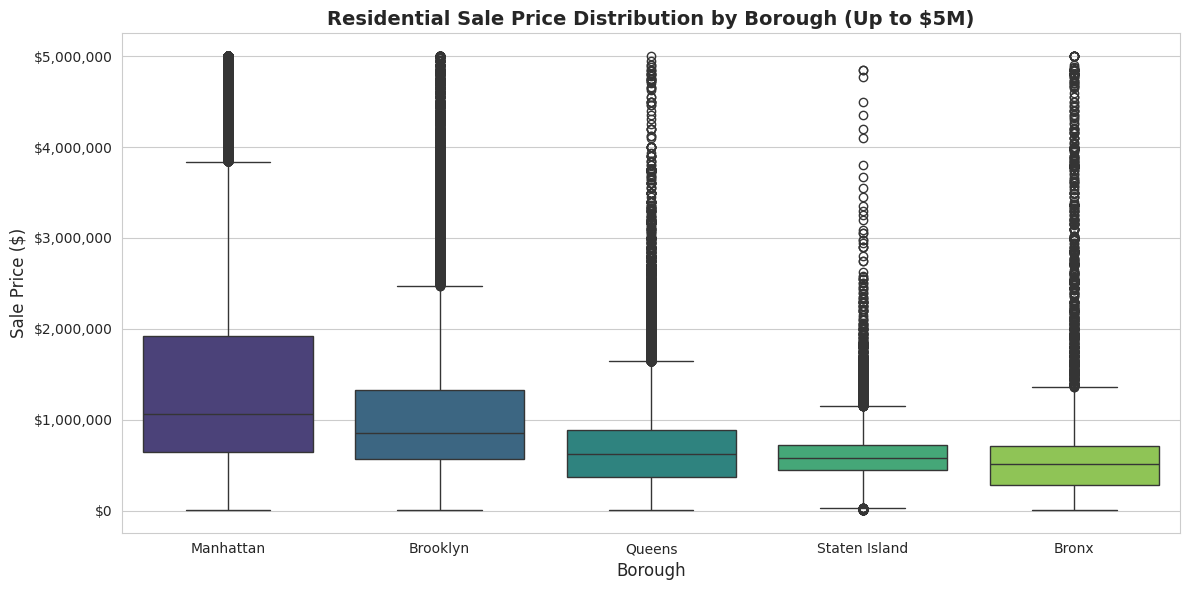

In [ ]:
# Cell 11: Box Plot - Price Distribution by Borough
fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(
    data=df_residential[df_residential["SALE PRICE"] <= 5_000_000],
    x="BOROUGH_NAME",
    y="SALE PRICE",
    order=borough_order,
    palette="viridis",
    ax=ax
)
ax.set_title("Residential Sale Price Distribution by Borough (Up to $5M)", fontsize=14, fontweight="bold")
ax.set_xlabel("Borough", fontsize=12)
ax.set_ylabel("Sale Price ($)", fontsize=12)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f"${x:,.0f}"))
plt.tight_layout()
plt.savefig("borough_price_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
df_sqft=df_residential[(df_residential['GROSS SQUARE FEET']>0) & (df_residential['GROSS SQUARE FEET'].notna())].copy()
df_sqft["PRICE_PER_SQFT"] = df_sqft["SALE PRICE"] / df_sqft["GROSS SQUARE FEET"]
most_recent_year = df_sqft["SALE DATE"].dt.year.max()
df_recent = df_sqft[df_sqft["SALE DATE"].dt.year == most_recent_year]

neighborhood_stats = df_recent.groupby(["BOROUGH_NAME", "NEIGHBORHOOD"]).agg(
    median_price_per_sqft=("PRICE_PER_SQFT", "median"),
    num_sales=("PRICE_PER_SQFT", "count")
).reset_index()

# Filter to neighborhoods with at least 20 sales for statistical reliability
neighborhood_stats = neighborhood_stats[neighborhood_stats["num_sales"] >= 20]
print(f"Analyzing {len(neighborhood_stats)} neighborhoods with 20+ sales in {most_recent_year}")

Analyzing 199 neighborhoods with 20+ sales in 2022


/tmp/ipykernel_6253/4178141271.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_6253/4178141271.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


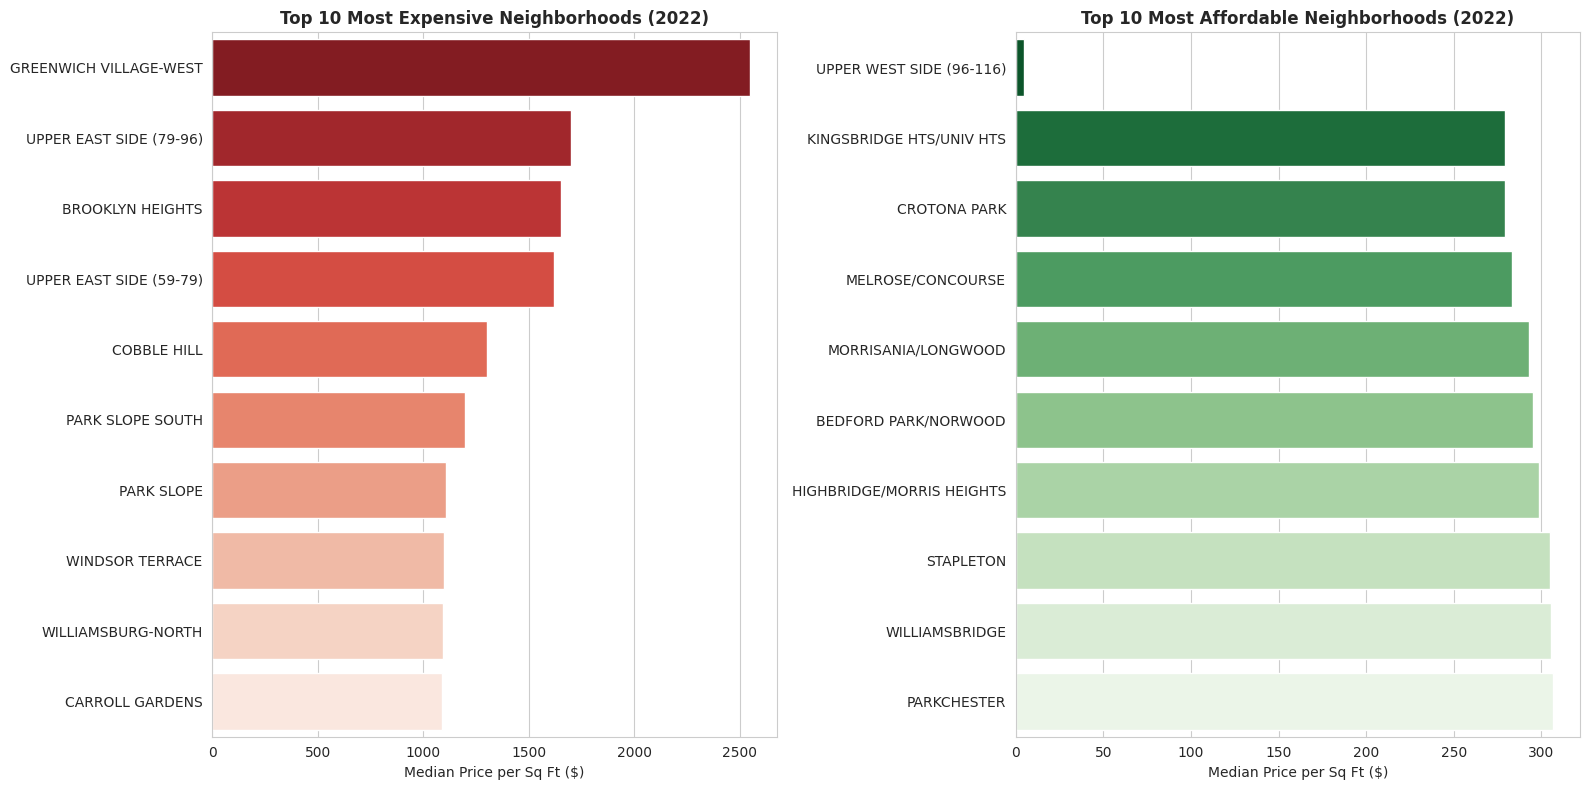

In [ ]:
# Cell 13: Top 10 Most and Least Expensive Neighborhoods
top_10_expensive = neighborhood_stats.nlargest(10, "median_price_per_sqft")
top_10_affordable = neighborhood_stats.nsmallest(10, "median_price_per_sqft")

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Most expensive
sns.barplot(
    data=top_10_expensive,
    y="NEIGHBORHOOD",
    x="median_price_per_sqft",
    palette="Reds_r",
    ax=axes[0]
)
axes[0].set_title(f"Top 10 Most Expensive Neighborhoods ({most_recent_year})", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Median Price per Sq Ft ($)", fontsize=10)
axes[0].set_ylabel("")

# Most affordable
sns.barplot(
    data=top_10_affordable,
    y="NEIGHBORHOOD",
    x="median_price_per_sqft",
    palette="Greens_r",
    ax=axes[1]
)
axes[1].set_title(f"Top 10 Most Affordable Neighborhoods ({most_recent_year})", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Median Price per Sq Ft ($)", fontsize=10)
axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig("neighborhood_comparison.png", dpi=150, bbox_inches="tight")
plt.show()